In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import create_engine

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

In [2]:
DATABASE_URL = (
    "postgresql+psycopg2://localhost/nyc_taxi"
)

engine = create_engine(DATABASE_URL)

In [3]:
query = """
SELECT
    pickup_date,
    pickup_hour,
    pickup_location_id,
    borough,
    zone,
    trip_count
FROM mv_hourly_zone_demand
ORDER BY
    pickup_location_id,
    pickup_date,
    pickup_hour
"""

df = pd.read_sql(
    query,
    engine
)

df.shape

(649877, 6)

In [4]:
df.head()

,pickup_date,pickup_hour,pickup_location_id,borough,zone,trip_count
0,2025-01-01,13,1,EWR,Newark Airport,1
1,2025-01-01,14,1,EWR,Newark Airport,1
2,2025-01-02,16,1,EWR,Newark Airport,1
3,2025-01-03,12,1,EWR,Newark Airport,1
4,2025-01-05,6,1,EWR,Newark Airport,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649877 entries, 0 to 649876
Data columns (total 6 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   pickup_date         649877 non-null  object
 1   pickup_hour         649877 non-null  int64 
 2   pickup_location_id  649877 non-null  int64 
 3   borough             649877 non-null  str   
 4   zone                649877 non-null  str   
 5   trip_count          649877 non-null  int64 
dtypes: int64(3), object(1), str(2)
memory usage: 44.1+ MB


In [6]:
df["timestamp"] = (
    pd.to_datetime(
        df["pickup_date"]
    )
    +
    pd.to_timedelta(
        df["pickup_hour"],
        unit="h"
    )
)

In [7]:
df[
    [
        "pickup_date",
        "pickup_hour",
        "timestamp"
    ]
].head()

,pickup_date,pickup_hour,timestamp
0,2025-01-01,13,2025-01-01 13:00:00
1,2025-01-01,14,2025-01-01 14:00:00
2,2025-01-02,16,2025-01-02 16:00:00
3,2025-01-03,12,2025-01-03 12:00:00
4,2025-01-05,6,2025-01-05 06:00:00


In [8]:
start_time = df["timestamp"].min()
end_time = df["timestamp"].max()

print(start_time)
print(end_time)

2025-01-01 00:00:00
2025-06-30 23:00:00


In [9]:
all_hours = pd.date_range(
    start=start_time,
    end=end_time,
    freq="h"
)


In [10]:
zones = (
    df[
        [
            "pickup_location_id",
            "borough",
            "zone"
        ]
    ]
    .drop_duplicates()
)

In [11]:
full_grid = (
    zones.assign(key=1)
    .merge(
        pd.DataFrame(
            {
                "timestamp": all_hours,
                "key": 1
            }
        ),
        on="key"
    )
    .drop(columns="key")
)

In [12]:
ml_df = full_grid.merge(
    df[
        [
            "pickup_location_id",
            "timestamp",
            "trip_count"
        ]
    ],
    on=[
        "pickup_location_id",
        "timestamp"
    ],
    how="left"
)

In [13]:
ml_df["trip_count"] = (
    ml_df["trip_count"]
    .fillna(0)
    .astype(int)
)

In [14]:
ml_df.shape

(1129440, 5)

In [15]:
ml_df = ml_df.sort_values(
    [
        "pickup_location_id",
        "timestamp"
    ]
).reset_index(drop=True)

In [16]:
ml_df["hour"] = (
    ml_df["timestamp"].dt.hour
)

ml_df["day_of_week"] = (
    ml_df["timestamp"].dt.dayofweek
)

ml_df["month"] = (
    ml_df["timestamp"].dt.month
)

ml_df["day"] = (
    ml_df["timestamp"].dt.day
)

ml_df["is_weekend"] = (
    ml_df["day_of_week"] >= 5
).astype(int)

ml_df["is_rush_hour"] = (
    ml_df["hour"].isin(
        [7, 8, 9, 16, 17, 18]
    )
).astype(int)

In [17]:
grouped = ml_df.groupby(
    "pickup_location_id"
)["trip_count"]

ml_df["lag_1h"] = grouped.shift(1)

ml_df["lag_2h"] = grouped.shift(2)

ml_df["lag_24h"] = grouped.shift(24)

ml_df["lag_168h"] = grouped.shift(
    24 * 7
)

In [18]:
grouped.rolling(24).mean()

pickup_location_id         
1                   0                NaN
                    1                NaN
                    2                NaN
                    3                NaN
                    4                NaN
                                 ...    
263                 1129435    72.750000
                    1129436    72.875000
                    1129437    72.625000
                    1129438    72.541667
                    1129439    72.750000
Name: trip_count, Length: 1129440, dtype: float64

In [19]:
ml_df["rolling_mean_3h"] = (
    ml_df
    .groupby("pickup_location_id")[
        "trip_count"
    ]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(3)
        .mean()
    )
)

In [20]:
ml_df["rolling_mean_24h"] = (
    ml_df
    .groupby("pickup_location_id")[
        "trip_count"
    ]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(24)
        .mean()
    )
)

In [21]:
ml_df["rolling_std_24h"] = (
    ml_df
    .groupby("pickup_location_id")[
        "trip_count"
    ]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(24)
        .std()
    )
)

In [22]:
lag_columns = [
    "lag_1h",
    "lag_2h",
    "lag_24h",
    "lag_168h",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "rolling_std_24h"
]

ml_df = ml_df.dropna(
    subset=lag_columns
).copy()

In [23]:
ml_df.shape

(1085760, 18)

In [24]:
ml_df[
    [
        "timestamp",
        "zone",
        "trip_count",
        "lag_1h",
        "lag_24h",
        "lag_168h",
        "rolling_mean_24h"
    ]
].head(10)

,timestamp,zone,trip_count,lag_1h,lag_24h,lag_168h,rolling_mean_24h
168,2025-01-08 00:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
169,2025-01-08 01:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
170,2025-01-08 02:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
171,2025-01-08 03:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
172,2025-01-08 04:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
173,2025-01-08 05:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
174,2025-01-08 06:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
175,2025-01-08 07:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
176,2025-01-08 08:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667
177,2025-01-08 09:00:00,Newark Airport,0,0.0,0.0,0.0,0.041667


In [26]:
FEATURES = [
    "pickup_location_id",

    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "is_rush_hour",

    "lag_1h",
    "lag_2h",
    "lag_24h",
    "lag_168h",

    "rolling_mean_3h",
    "rolling_mean_24h",
    "rolling_std_24h"
]

TARGET = "trip_count"

In [27]:
train = ml_df[
    ml_df["timestamp"]
    < "2025-06-01"
].copy()

test = ml_df[
    ml_df["timestamp"]
    >= "2025-06-01"
].copy()

In [28]:
print(
    "Train:",
    train["timestamp"].min(),
    "→",
    train["timestamp"].max()
)

print(
    "Test:",
    test["timestamp"].min(),
    "→",
    test["timestamp"].max()
)

print(
    "Train rows:",
    f"{len(train):,}"
)

print(
    "Test rows:",
    f"{len(test):,}"
)

Train: 2025-01-08 00:00:00 → 2025-05-31 23:00:00
Test: 2025-06-01 00:00:00 → 2025-06-30 23:00:00
Train rows: 898,560
Test rows: 187,200


In [29]:
def evaluate_model(
    name,
    y_true,
    y_pred
):
    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [30]:
y_test = test[TARGET]

baseline_pred = test[
    "lag_168h"
]

results = []

results.append(
    evaluate_model(
        "Weekly Historical Baseline",
        y_test,
        baseline_pred
    )
)

In [31]:
pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Weekly Historical Baseline,4.949744,14.563827,0.932828


In [32]:
X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

In [33]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

In [34]:
linear_pred = np.maximum(
    linear_pred,
    0
)

In [35]:
results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    )
)

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Weekly Historical Baseline,4.949744,14.563827,0.932828
1,Linear Regression,3.980943,10.951051,0.962021


In [36]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)

In [37]:
rf_model.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [38]:
rf_pred = rf_model.predict(
    X_test
)

In [39]:
results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Weekly Historical Baseline,4.949744,14.563827,0.932828
1,Linear Regression,3.980943,10.951051,0.962021
2,Random Forest,3.657768,10.244842,0.966761


In [40]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=500,
    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,
    colsample_bytree=0.8,

    random_state=42,
    n_jobs=-1
)

In [41]:
xgb_model.fit(
    X_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [42]:
xgb_pred = xgb_model.predict(
    X_test
)

xgb_pred = np.maximum(
    xgb_pred,
    0
)

In [43]:
results.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_pred
    )
)

In [44]:
results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

results_df

,Model,MAE,RMSE,R2
0,XGBoost,3.554832,9.654893,0.970479
1,Random Forest,3.657768,10.244842,0.966761
2,Linear Regression,3.980943,10.951051,0.962021
3,Weekly Historical Baseline,4.949744,14.563827,0.932828


In [45]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": xgb_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

importance

,feature,importance
9,lag_168h,0.668918
6,lag_1h,0.245414
8,lag_24h,0.036435
10,rolling_mean_3h,0.018346
12,rolling_std_24h,0.004736
1,hour,0.004601
5,is_rush_hour,0.004226
0,pickup_location_id,0.004075
2,day_of_week,0.003680
7,lag_2h,0.003173


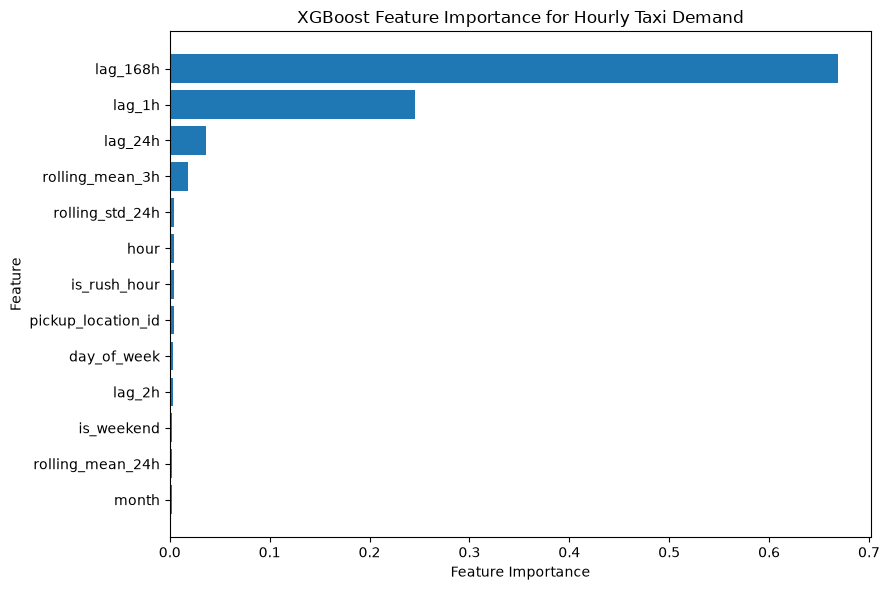

In [46]:
plt.figure(figsize=(9, 6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "XGBoost Feature Importance for Hourly Taxi Demand"
)

plt.tight_layout()

plt.savefig(
    "../images/forecast_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [47]:
test = test.copy()

test["predicted_demand"] = xgb_pred
test["absolute_error"] = np.abs(
    test["trip_count"]
    - test["predicted_demand"]
)

In [48]:
zone_results = test[
    test["zone"] == "Midtown Center"
].copy()

plot_data = zone_results[
    (zone_results["timestamp"] >= "2025-06-01")
    &
    (zone_results["timestamp"] < "2025-06-08")
]

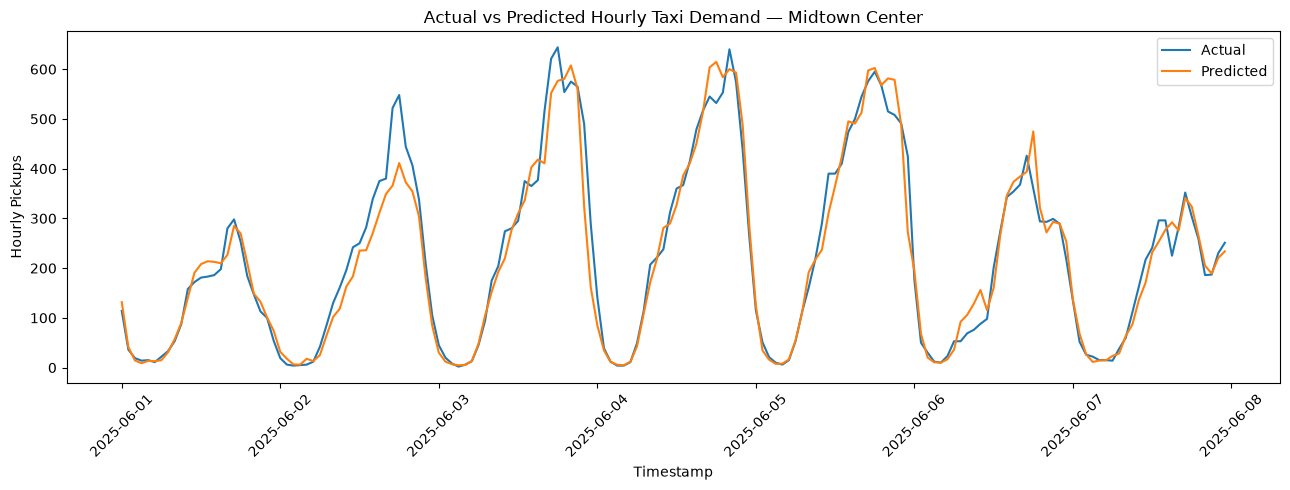

In [49]:
plt.figure(figsize=(13, 5))

plt.plot(
    plot_data["timestamp"],
    plot_data["trip_count"],
    label="Actual"
)

plt.plot(
    plot_data["timestamp"],
    plot_data["predicted_demand"],
    label="Predicted"
)

plt.xlabel("Timestamp")
plt.ylabel("Hourly Pickups")

plt.title(
    "Actual vs Predicted Hourly Taxi Demand — Midtown Center"
)

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../images/actual_vs_predicted.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [50]:
test[
    [
        "timestamp",
        "borough",
        "zone",
        "trip_count",
        "predicted_demand",
        "absolute_error"
    ]
].sort_values(
    "absolute_error",
    ascending=False
).head(20)

,timestamp,borough,zone,trip_count,predicted_demand,absolute_error
559848,2025-06-09 00:00:00,Queens,JFK Airport,600,303.870087,296.129913
686084,2025-06-19 20:00:00,Manhattan,Midtown Center,283,554.563965,271.563965
559813,2025-06-07 13:00:00,Queens,JFK Airport,493,240.712601,252.287399
559815,2025-06-07 15:00:00,Queens,JFK Airport,659,428.628784,230.371216
794589,2025-06-15 21:00:00,Manhattan,Penn Station/Madison Sq West,545,323.096680,221.903320
559820,2025-06-07 20:00:00,Queens,JFK Airport,291,510.371155,219.371155
686081,2025-06-19 17:00:00,Manhattan,Midtown Center,389,597.412354,208.412354
586344,2025-06-27 00:00:00,Queens,LaGuardia Airport,439,231.103027,207.896973
586247,2025-06-22 23:00:00,Queens,LaGuardia Airport,488,292.339172,195.660828
342744,2025-06-13 00:00:00,Manhattan,East Village,294,485.803345,191.803345


In [51]:
borough_error = (
    test
    .groupby("borough")
    .agg(
        observations=("trip_count", "size"),
        actual_avg_demand=("trip_count", "mean"),
        predicted_avg_demand=("predicted_demand", "mean"),
        mae=("absolute_error", "mean")
    )
    .round(2)
    .sort_values("mae", ascending=False)
)

borough_error

,observations,actual_avg_demand,predicted_avg_demand,mae
borough,,,,
Manhattan,48240,67.48,67.379997,9.53
Queens,49680,7.79,7.850000,2.15
Brooklyn,43920,3.50,3.520000,1.63
Bronx,30960,1.03,1.050000,0.81
EWR,720,0.03,0.110000,0.14
Staten Island,13680,0.03,0.110000,0.13


In [52]:
zone_error = (
    test
    .groupby(
        [
            "borough",
            "zone"
        ]
    )
    .agg(
        observations=("trip_count", "size"),
        avg_demand=("trip_count", "mean"),
        mae=("absolute_error", "mean")
    )
    .round(2)
    .sort_values(
        "mae",
        ascending=False
    )
)

zone_error.head(20)

observations  avg_demand    mae
borough   zone                                                         
Queens    JFK Airport                            720      233.84  35.14
          LaGuardia Airport                      720      150.42  31.23
Manhattan Midtown Center                         720      225.89  25.81
          Penn Station/Madison Sq West           720      165.45  24.35
          Upper East Side South                  720      230.01  23.75
          Upper East Side North                  720      198.12  20.72
          East Village                           720      137.14  20.15
          Lincoln Square East                    720      145.35  20.06
          Times Sq/Theatre District              720      161.39  19.95
          Midtown East                           720      165.23  18.01
          East Chelsea                           720      136.87  16.80
          Clinton East                           720      129.93  16.59
          Union Sq                               720      140.57  16.26
          West Village                           720      116.18  15.91
          Murray Hill                            720      144.40  15.88
          Midtown North                          720      133.44  15.73
          Upper West Side South                  720      127.75  15.53
          West Chelsea/Hudson Yards              720       96.11  14.54
          Midtown South                          720      112.05  13.59
          Central Park                           720       71.04  12.66

In [53]:
forecast_output = test[
    [
        "timestamp",
        "pickup_location_id",
        "borough",
        "zone",
        "trip_count",
        "predicted_demand",
        "absolute_error"
    ]
].copy()

forecast_output.rename(
    columns={
        "trip_count": "actual_demand"
    },
    inplace=True
)

In [54]:
forecast_output["date"] = (
    forecast_output["timestamp"].dt.date
)

forecast_output["hour"] = (
    forecast_output["timestamp"].dt.hour
)

forecast_output["day_of_week"] = (
    forecast_output["timestamp"].dt.day_name()
)

In [55]:
forecast_output.to_csv(
    "../data/processed/demand_forecast_june_2025.csv",
    index=False
)

In [56]:
results_df.to_csv(
    "../data/processed/model_metrics.csv",
    index=False
)

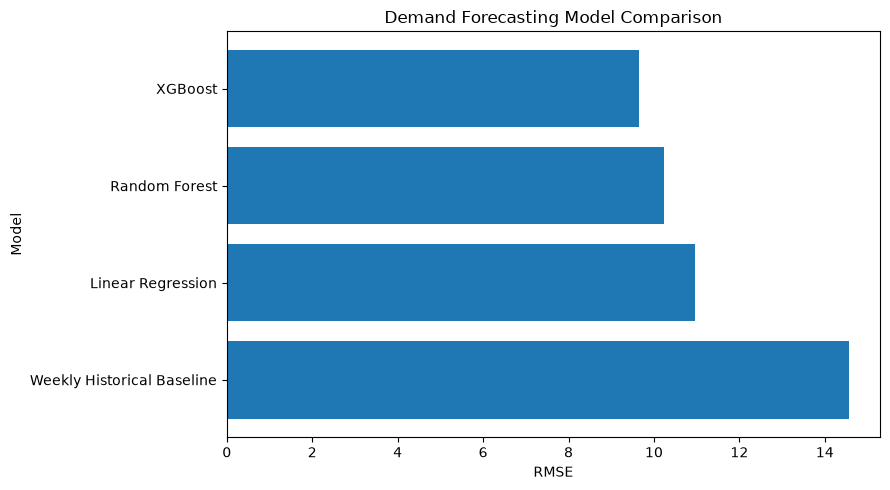

In [57]:
plot_results = results_df.sort_values(
    "RMSE",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_results["Model"],
    plot_results["RMSE"]
)

plt.xlabel("RMSE")
plt.ylabel("Model")

plt.title(
    "Demand Forecasting Model Comparison"
)

plt.tight_layout()

plt.savefig(
    "../images/model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
## Model Results

Four forecasting approaches were evaluated using a chronological train-test design, with January–May 2025 used for training and June 2025 reserved as an unseen test period.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| XGBoost | 3.55 | 9.65 | 0.970 |
| Random Forest | 3.66 | 10.24 | 0.967 |
| Linear Regression | 3.98 | 10.95 | 0.962 |
| Weekly Historical Baseline | 4.95 | 14.56 | 0.933 |

XGBoost achieved the strongest overall forecasting performance, reducing MAE by approximately 28% and RMSE by approximately 34% compared with the weekly historical baseline.

The model achieved an MAE of approximately 3.55 pickups per zone-hour and explained approximately 97% of the variance in demand during the June holdout period.

The improvement over the historical baseline demonstrates that combining recent demand, daily and weekly lag patterns, rolling demand statistics, temporal characteristics, and location information provides additional predictive value beyond simply assuming that demand will repeat from the previous week.

### Modeling Methodology

- Forecasting unit: taxi zone × hour
- Training period: January–May 2025
- Test period: June 2025
- Zero-demand zone-hours were explicitly represented rather than treated as missing observations.
- Lag and rolling features were shifted to ensure that only information available before the prediction timestamp was used.
- A chronological split was used instead of random train-test splitting to better simulate real-world forecasting.
- A weekly historical baseline was included to determine whether machine-learning models provided meaningful improvement over a simple operational forecasting strategy.

### Limitations

The model uses historical taxi-demand and calendar features and does not incorporate external factors such as weather, holidays, major events, subway disruptions, traffic incidents, or flight schedules. These variables could improve performance during unusual demand periods.